<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/08-visualization/01_lesson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 8: Visualization

So far in this course, every chart has been drawn with text characters: `#` bars for learning curves, a grid of `.` and `#` for decision boundaries, shaded characters for digits. That kept us focused on the data, but real work needs real charts, for two reasons:

1. **To understand data.** Summary statistics can hide almost anything. A chart often shows in a second what a table of numbers never would.
2. **To communicate results.** A model's value has to be explained to people who won't read your code. A clear chart does that better than any paragraph.

This module covers **Matplotlib**, the foundation of plotting in Python, and **Seaborn**, which builds on it for statistical charts. Just as importantly, it covers how to choose the right chart and how to make it honest and readable, because a chart can mislead as easily as it can inform.

**Contents**

1. Why look at the data at all?
2. The anatomy of a Matplotlib figure
3. A house style
4. Choosing the right chart
5. Distributions
6. Relationships, and a paradox
7. Comparing groups
8. Change over time
9. Matrices: heatmaps
10. Seaborn
11. Figures for reports

## Setup

The data is the penguin dataset from Module 5, loaded with pandas as in Module 7.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

DATA_URL = "https://raw.githubusercontent.com/anupbagale/python-for-ai-ml/main/05-files-and-data/data/penguins.csv"
local = Path("data/penguins.csv")
penguins = pd.read_csv(local if local.exists() else DATA_URL).dropna(subset=["bill_length_mm", "body_mass_g"])
SPECIES = ["Adelie", "Chinstrap", "Gentoo"]
print(penguins.shape)

(342, 8)


## 1. Why look at the data at all?

In 1973, the statistician Francis Anscombe published four tiny datasets, now known as **Anscombe's quartet**. Here are their summary statistics:

In [2]:
anscombe = pd.DataFrame({
    "x1": [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5],
    "y1": [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68],
    "y2": [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74],
    "y3": [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73],
    "x4": [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8],
    "y4": [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89],
})
pairs = [("x1", "y1"), ("x1", "y2"), ("x1", "y3"), ("x4", "y4")]

for i, (xc, yc) in enumerate(pairs, start=1):
    x, y = anscombe[xc], anscombe[yc]
    print(f"dataset {i}: mean x {x.mean():.2f}, mean y {y.mean():.2f}, "
          f"var y {y.var():.2f}, correlation {x.corr(y):.3f}")

dataset 1: mean x 9.00, mean y 7.50, var y 4.13, correlation 0.816
dataset 2: mean x 9.00, mean y 7.50, var y 4.13, correlation 0.816
dataset 3: mean x 9.00, mean y 7.50, var y 4.12, correlation 0.816
dataset 4: mean x 9.00, mean y 7.50, var y 4.12, correlation 0.817


Nearly identical. Same means, same variance, same correlation. If you only looked at these numbers, and even fitted a straight line to each, you'd conclude the four datasets are the same. Now look at them:

In [3]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

That cell set up the plotting style used for the rest of the course. Section 3 explains every choice in it. For now, here's the quartet:

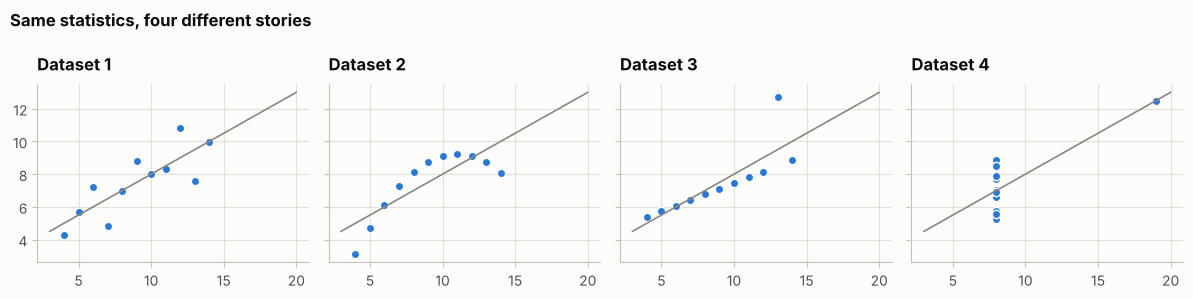

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharex=True, sharey=True)
for ax, (i, (xc, yc)) in zip(axes, enumerate(pairs, start=1)):
    x, y = anscombe[xc], anscombe[yc]
    ax.scatter(x, y, color=PALETTE[0], s=36, edgecolors=SURFACE, linewidths=1)
    slope, intercept = np.polyfit(x, y, 1)
    xs = np.array([3, 20])
    ax.plot(xs, slope * xs + intercept, color=MUTED, linewidth=1.2)
    ax.set_title(f"Dataset {i}")
fig.suptitle("Same statistics, four different stories", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

Four completely different situations:

1. a noisy straight-line relationship, which is what the statistics suggest
2. a perfect curve, which a straight line describes badly
3. a perfect line, with one outlier dragging the fit
4. no relationship at all, with one extreme point creating the entire correlation

Every one of these would need different handling before a model sees it. Summary statistics alone can't tell them apart, and a chart does it instantly. That's the strongest argument for plotting your data before modelling it.

## 2. The anatomy of a Matplotlib figure

Matplotlib has two ways of working. The quick one uses `plt.plot(...)`, `plt.title(...)` and so on, acting on "the current chart". The one to learn is the **object-oriented** style, because it stays clear when a figure has several panels:

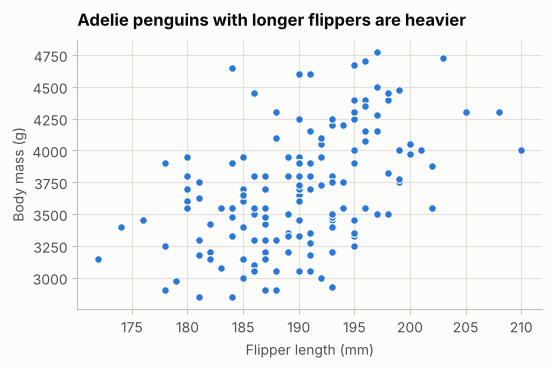

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.5))

adelie = penguins[penguins["species"] == "Adelie"]
ax.scatter(adelie["flipper_length_mm"], adelie["body_mass_g"],
           color=PALETTE[0], s=30, edgecolors=SURFACE, linewidths=0.8)

ax.set_title("Adelie penguins with longer flippers are heavier")
ax.set_xlabel("Flipper length (mm)")
ax.set_ylabel("Body mass (g)")
plt.show()

The two objects:

- A **Figure** is the whole image, the canvas. It can hold one or many panels.
- An **Axes** (note the "es": it's one object, not several axes) is one panel with its own x and y axis, title and marks. You draw on it with methods like `ax.scatter`, `ax.plot`, `ax.bar` and `ax.hist`, and label it with `ax.set_title`, `ax.set_xlabel` and so on.

`plt.subplots(rows, cols)` creates a figure and a grid of axes in one call. With several panels, `axes` is a NumPy array of `Axes` objects, which is what made the Anscombe loop above so simple.

Notice the title. It doesn't say "Flipper length vs body mass", which just repeats the axis labels. It states what the chart shows. That one habit makes charts much more useful, and section 11 comes back to it.

## 3. A house style

The setup cell above changed Matplotlib's defaults. Every choice in it has a reason, and they're worth knowing because they apply to any chart, in any tool.

**The data should be the loudest thing on the chart.** Gridlines are thin and pale, the top and right borders are removed, and the axis lines are light grey. They help you read values without competing with the marks.

**Colours have jobs.** There are only four, and each has one rule:

| job | example | rule |
|---|---|---|
| **identity** (categorical) | which species | a fixed set of distinct hues, always in the same order |
| **magnitude** (sequential) | a count in a heatmap cell | one hue, from light to dark |
| **polarity** (diverging) | a correlation from -1 to +1 | two opposite hues, with a neutral grey at zero |
| **state** | good / warning / bad | reserved colours, always with a label or icon |

A common mistake is using a rainbow for magnitude. Rainbows have no natural order (is green more than yellow?), so readers can't tell which values are bigger.

**The categorical colours are checked for colour blindness.** About 1 in 12 men and 1 in 200 women have some form of colour vision deficiency, most often difficulty telling red from green. The `PALETTE` above was checked with a tool that simulates the common types and measures how distinguishable each pair of colours stays. Its first three colours remain distinct even in a scatter plot, where any two might end up side by side, which is why the three penguin species get exactly those. Even so, the charts below also give each species its own marker shape and a legend, so colour is never the only way to tell them apart.

**Colour follows the thing, not its position.** Adelie is always blue, Chinstrap always orange, Gentoo always aqua, in every chart in this module. If a filter removed Adelie from a chart, Chinstrap would stay orange rather than moving up to blue. That consistency lets readers learn the colours once.

**Text stays in ink colours.** Labels and titles are near-black or grey, never the colour of a series. Light colours like yellow and aqua are hard to read as text.

Here are the palette and the two colour scales:

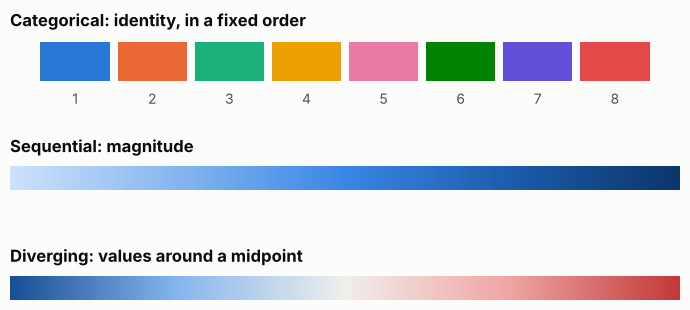

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(7, 3.2), gridspec_kw={"height_ratios": [1, 0.6, 0.6]})

for i, colour in enumerate(PALETTE):
    axes[0].bar(i, 1, color=colour, width=0.9)
    axes[0].text(i, -0.25, f"{i + 1}", ha="center", va="top", color=INK_2)
axes[0].set_title("Categorical: identity, in a fixed order")

gradient = np.linspace(0, 1, 256)[None, :]
axes[1].imshow(gradient, aspect="auto", cmap=SEQUENTIAL)
axes[1].set_title("Sequential: magnitude")
axes[2].imshow(gradient, aspect="auto", cmap=DIVERGING)
axes[2].set_title("Diverging: values around a midpoint")

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.tight_layout()
plt.show()

`plt.rcParams` holds Matplotlib's defaults, and changing it once at the top of a notebook styles every chart after it. That's much better than setting colours and fonts chart by chart: it's consistent, and you can change the whole look in one place.

## 4. Choosing the right chart

Start from the question, not the chart type:

| question | chart |
|---|---|
| How are the values of one variable spread out? | histogram, box plot, violin |
| How does one variable relate to another? | scatter plot |
| How do groups compare on one number? | bar chart (sorted), or dot plot |
| How does something change over time? | line chart |
| How do many pairs of variables relate? | heatmap of correlations, or a pair plot |
| What's the single number that matters? | no chart: just state the number |

That last row is easy to forget. If the message is "accuracy went from 81% to 94%", a sentence says it better than a chart with two bars.

Two rules hold for every chart type:

- **One y-axis.** Charts with two different y-scales, one on each side, let the person making the chart line the two series up however they like, which creates relationships that aren't really there. If two measures have different units, use two charts, or convert both to a common scale (section 8 shows how).
- **Bars start at zero.** A bar's length *is* its value. If the axis starts at 3,000, a bar for 3,700 looks almost twice as long as one for 3,350 (section 7 shows this).

## 5. Distributions

A **histogram** splits the range of values into bins and counts how many fall in each:

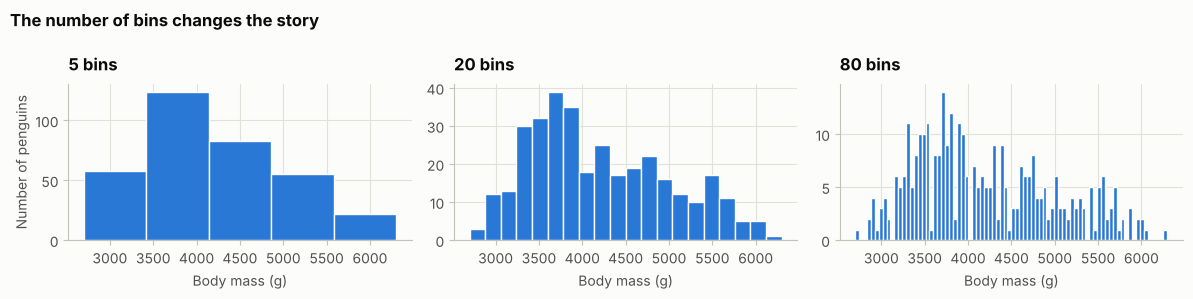

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=False)
for ax, bins in zip(axes, [5, 20, 80]):
    ax.hist(penguins["body_mass_g"], bins=bins, color=PALETTE[0], edgecolor=SURFACE, linewidth=1)
    ax.set_title(f"{bins} bins")
    ax.set_xlabel("Body mass (g)")
axes[0].set_ylabel("Number of penguins")
fig.suptitle("The number of bins changes the story", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

With 5 bins, the distribution looks like one lump. With 20, there's a hint of two groups, light and heavy. With 80, it's mostly noise. The bin count is a choice you make, and it can hide or invent structure, so try a few before trusting the shape.

`edgecolor=SURFACE` draws a thin line in the background colour between bars. That small gap separates adjacent bars far more cleanly than a dark outline would.

That hint of two groups is real. Splitting by species shows where it comes from:

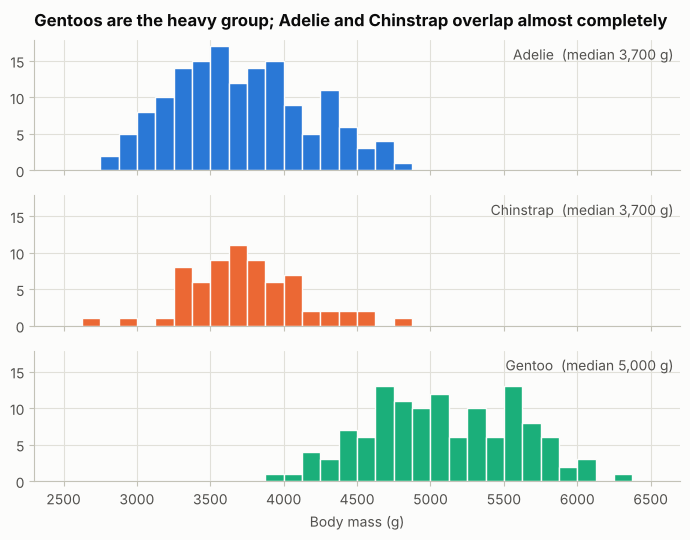

In [8]:
MARKERS = {"Adelie": "o", "Chinstrap": "s", "Gentoo": "^"}
COLOURS = dict(zip(SPECIES, PALETTE))

fig, axes = plt.subplots(3, 1, figsize=(7, 5.5), sharex=True, sharey=True)
bins = np.linspace(2500, 6500, 33)
for ax, sp in zip(axes, SPECIES):
    values = penguins.loc[penguins["species"] == sp, "body_mass_g"]
    ax.hist(values, bins=bins, color=COLOURS[sp], edgecolor=SURFACE, linewidth=1)
    ax.text(0.99, 0.85, f"{sp}  (median {values.median():,.0f} g)", transform=ax.transAxes,
            ha="right", color=INK_2)
axes[-1].set_xlabel("Body mass (g)")
axes[0].set_title("Gentoos are the heavy group; Adelie and Chinstrap overlap almost completely")
fig.tight_layout()
plt.show()

This is a **small multiples** layout: the same chart repeated for each group, with **shared axes** (`sharex=True, sharey=True`) so they can be compared directly. Overlapping all three histograms in one panel would be harder to read, because the bars hide each other.

Two details:

- `bins = np.linspace(...)` gives every panel *the same* bin edges. If each histogram chose its own bins, the bars wouldn't line up between panels and the comparison would be misleading.
- `transform=ax.transAxes` places the text in axes coordinates, where (0, 0) is the bottom-left of the panel and (1, 1) the top-right, rather than in data units. That's the easy way to put a label in a corner.

### Box plots

A **box plot** summarises a distribution in five numbers: the box spans the middle 50% of values (from the 25th to the 75th percentile), the line inside is the median, and the whiskers reach the rest of the data, with points beyond them drawn individually as possible outliers. It's compact, which makes comparing many groups easy:

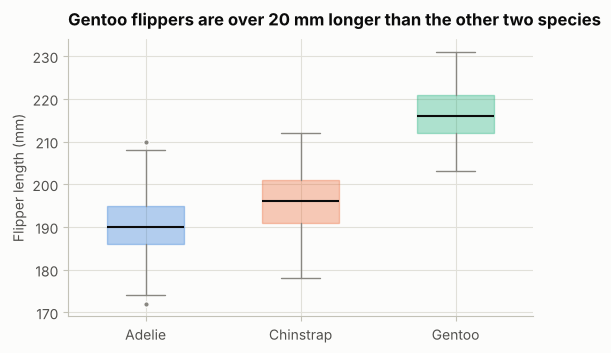

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.6))
data = [penguins.loc[penguins["species"] == sp, "flipper_length_mm"] for sp in SPECIES]
box = ax.boxplot(data, widths=0.5, patch_artist=True,
                 medianprops={"color": INK, "linewidth": 1.5},
                 whiskerprops={"color": MUTED}, capprops={"color": MUTED},
                 flierprops={"marker": "o", "markersize": 4, "markerfacecolor": MUTED, "markeredgecolor": SURFACE})
for patch, sp in zip(box["boxes"], SPECIES):
    patch.set_facecolor(COLOURS[sp])
    patch.set_alpha(0.35)
    patch.set_edgecolor(COLOURS[sp])
ax.set_xticks([1, 2, 3], SPECIES)
ax.set_ylabel("Flipper length (mm)")
ax.set_title("Gentoo flippers are over 20 mm longer than the other two species")
plt.show()

The trade-off: box plots hide the shape of the distribution. Two groups with very different shapes, say one with a single peak and one with two, can produce identical boxes. When the shape matters, use histograms or a violin plot (section 10).

## 6. Relationships, and a paradox

Scatter plots show how two variables relate. Here's bill length against bill depth for all penguins, with a line fitted through them:

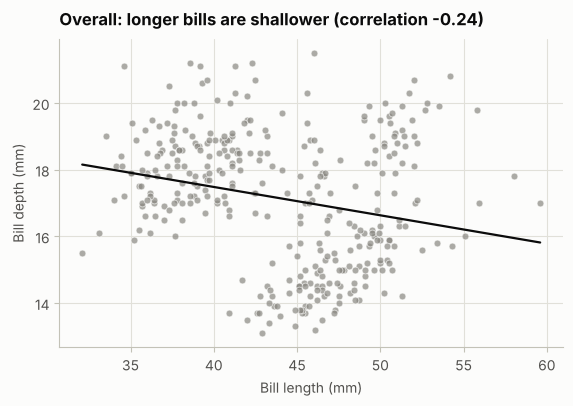

In [10]:
x, y = penguins["bill_length_mm"], penguins["bill_depth_mm"]
slope, intercept = np.polyfit(x, y, 1)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(x, y, color=MUTED, s=24, alpha=0.7, edgecolors=SURFACE, linewidths=0.6)
xs = np.array([x.min(), x.max()])
ax.plot(xs, slope * xs + intercept, color=INK, linewidth=1.6)
ax.set_xlabel("Bill length (mm)")
ax.set_ylabel("Bill depth (mm)")
ax.set_title(f"Overall: longer bills are shallower (correlation {x.corr(y):.2f})")
plt.show()

A clear negative trend: penguins with longer bills seem to have shallower ones. Now colour the same points by species, and fit a separate line for each:

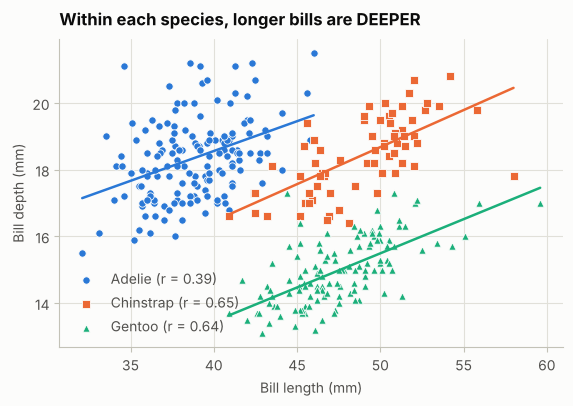

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for sp in SPECIES:
    group = penguins[penguins["species"] == sp]
    gx, gy = group["bill_length_mm"], group["bill_depth_mm"]
    ax.scatter(gx, gy, color=COLOURS[sp], marker=MARKERS[sp], s=28,
               edgecolors=SURFACE, linewidths=0.6, label=f"{sp} (r = {gx.corr(gy):.2f})")
    s, c = np.polyfit(gx, gy, 1)
    line_x = np.array([gx.min(), gx.max()])
    ax.plot(line_x, s * line_x + c, color=COLOURS[sp], linewidth=1.8)
ax.set_xlabel("Bill length (mm)")
ax.set_ylabel("Bill depth (mm)")
ax.set_title("Within each species, longer bills are DEEPER")
ax.legend(loc="lower left")
plt.show()

The relationship flips. **Within every species, longer bills are deeper**: bigger penguins have bigger bills in both directions, which makes sense. The overall negative trend only appears because the species sit in different places. Gentoos have long but shallow bills, Adelies short but deep ones. Pooling them creates a trend that's true of no single species.

This is **Simpson's paradox**: a trend that appears in combined data reverses, or disappears, when the data is split into its natural groups. It shows up in real analyses all the time, from medical studies to university admissions, and it's a strong reason to plot data by group before drawing conclusions. A model given only bill length and depth, without species, would learn the misleading overall relationship.

Notice the encoding: each species has a colour **and** a marker shape, and the legend names them. Someone who can't tell orange from aqua can still read this chart.

### Too many points

With thousands of points, a scatter plot turns into a solid blob, and you can't see where the points are densest. Two fixes: make the points small and partly transparent (`alpha`), or count points in a grid with `hexbin`:

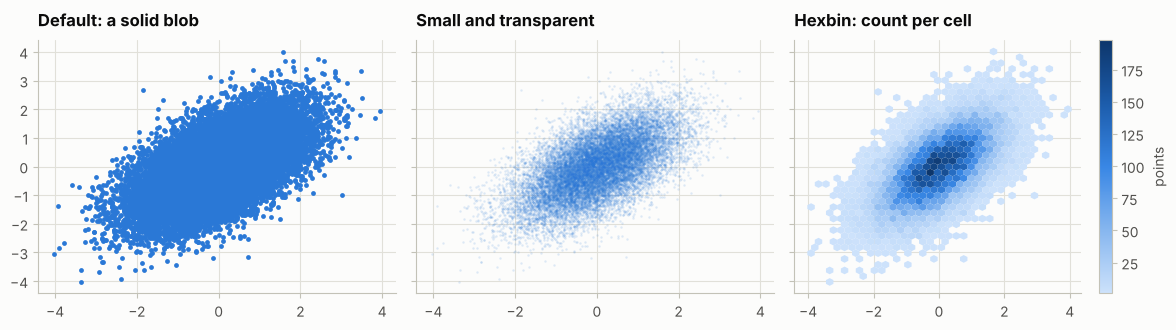

In [12]:
rng = np.random.default_rng(0)
many_x = rng.normal(0, 1, 20_000)
many_y = 0.6 * many_x + rng.normal(0, 0.8, 20_000)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharex=True, sharey=True)
axes[0].scatter(many_x, many_y, s=12, color=PALETTE[0])
axes[0].set_title("Default: a solid blob")
axes[1].scatter(many_x, many_y, s=3, alpha=0.15, color=PALETTE[0], linewidths=0)
axes[1].set_title("Small and transparent")
hb = axes[2].hexbin(many_x, many_y, gridsize=35, cmap=SEQUENTIAL, mincnt=1)
axes[2].set_title("Hexbin: count per cell")
fig.colorbar(hb, ax=axes[2], label="points")
fig.tight_layout()
plt.show()

The hexbin uses the **sequential** scale, since it shows magnitude: lighter cells have fewer points, darker cells more.

## 7. Comparing groups

To compare one number across groups, use a bar chart. Three habits make bar charts much easier to read:

1. **Sort the bars** by value, unless the categories have a natural order (like months).
2. **Make them horizontal** when the labels are long, so the labels can be read without tilting your head.
3. **Label the values at the bar ends** if the exact numbers matter, and you can then drop the gridlines.

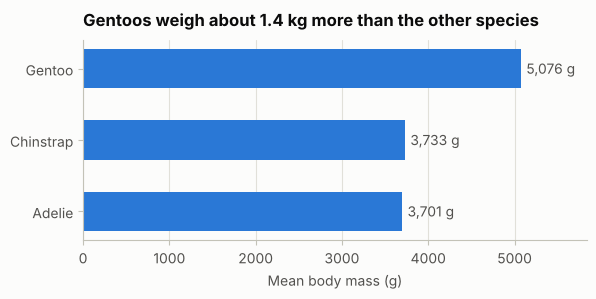

In [13]:
means = penguins.groupby("species")["body_mass_g"].mean().sort_values()

fig, ax = plt.subplots(figsize=(6.5, 2.6))
bars = ax.barh(means.index, means.values, color=PALETTE[0], height=0.55)
for bar, value in zip(bars, means.values):
    ax.text(value + 60, bar.get_y() + bar.get_height() / 2, f"{value:,.0f} g",
            va="center", color=INK_2)
ax.set_xlim(0, means.max() * 1.15)
ax.set_xlabel("Mean body mass (g)")
ax.set_title("Gentoos weigh about 1.4 kg more than the other species")
ax.grid(axis="y", visible=False)
plt.show()

All the bars are one colour. They show a single measure, so the colour carries no information, and giving each bar its own colour would suggest a difference that isn't there. (The species colours appear when the chart is *about* telling species apart, as in the scatter plot.)

### Why bars start at zero

Here's the same data with two different axes:

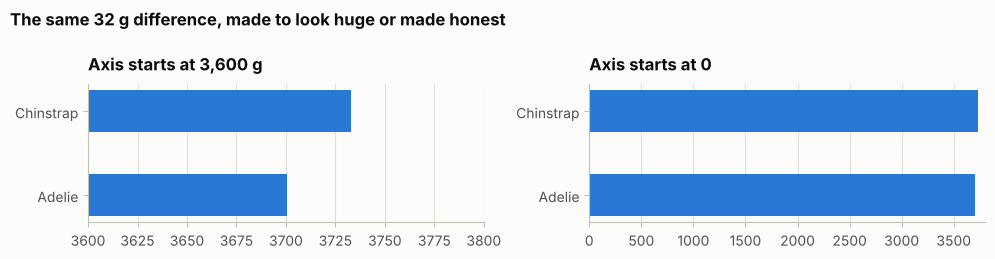

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 2.6))
two = means.loc[["Adelie", "Chinstrap"]]
for ax, start, title in [(axes[0], 3600, "Axis starts at 3,600 g"), (axes[1], 0, "Axis starts at 0")]:
    ax.barh(two.index, two.values, color=PALETTE[0], height=0.5)
    ax.set_xlim(start, 3800)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
fig.suptitle("The same 32 g difference, made to look huge or made honest", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

On the left, the Chinstrap bar looks more than twice as long as the Adelie bar. The real difference is under 1%. A truncated axis on a bar chart is one of the most common ways charts mislead, sometimes on purpose. Line charts and scatter plots *can* use a zoomed-in axis, because they show position rather than length, but bars can't.

## 8. Change over time

Line charts show change over time. Let's simulate a year of daily visits to a website, with a weekly pattern, slow growth, and random noise:

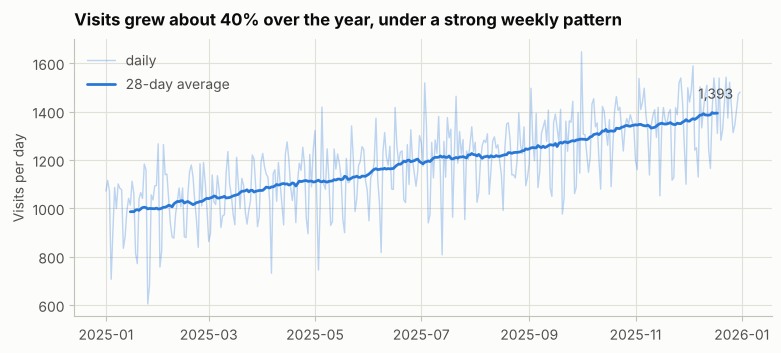

In [15]:
days = pd.date_range("2025-01-01", "2025-12-31", freq="D")
rng = np.random.default_rng(1)
weekly = np.where(days.dayofweek >= 5, -180, 40)                      # quieter at weekends
visits = pd.Series(1000 + np.arange(len(days)) * 1.2 + weekly + rng.normal(0, 90, len(days)), index=days)

rolling = visits.rolling(28, center=True).mean()

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(visits.index, visits.values, color=PALETTE[0], alpha=0.3, linewidth=1, label="daily")
ax.plot(rolling.index, rolling.values, color=PALETTE[0], linewidth=2, label="28-day average")
ax.set_ylabel("Visits per day")
ax.set_title("Visits grew about 40% over the year, under a strong weekly pattern")
ax.legend(loc="upper left")
ax.text(rolling.index[-15], rolling.dropna().iloc[-1] + 60, f"{rolling.dropna().iloc[-1]:,.0f}",
        color=INK_2, ha="center")
plt.show()

The raw daily line is drawn faintly, and the smoothed line on top carries the story. Showing both is honest: the reader sees the trend and how noisy the underlying data is. `rolling(28, center=True)` averages each day with the two weeks either side; with `center=False` the average would lag behind the data.

When the x values are dates, Matplotlib formats the axis as dates automatically.

### Two measures with different units

Suppose you also want to show revenue per day, which is in a completely different range. The tempting option is a second y-axis on the right. As section 4 explained, it lets the chart maker align the two lines however they like, creating a visual relationship that isn't in the data. The honest alternative is to **index** both series: divide each by its own starting value, so both start at 100 and the y-axis means "relative to the start":

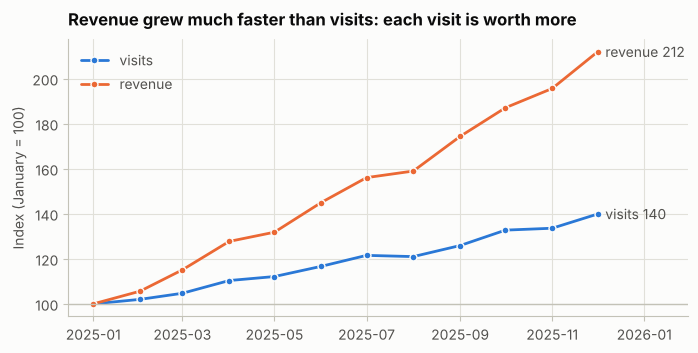

In [16]:
revenue = visits * (2.0 + np.linspace(0, 1.2, len(days))) + rng.normal(0, 150, len(days))
monthly = pd.DataFrame({"visits": visits, "revenue": revenue}).resample("MS").mean()
indexed = monthly / monthly.iloc[0] * 100

fig, ax = plt.subplots(figsize=(8, 3.6))
for i, column in enumerate(indexed.columns):
    ax.plot(indexed.index, indexed[column], color=PALETTE[i], linewidth=2, marker="o", markersize=5,
            markeredgecolor=SURFACE, label=column)
    ax.text(indexed.index[-1], indexed[column].iloc[-1], f"  {column} {indexed[column].iloc[-1]:.0f}",
            va="center", color=INK_2)
ax.axhline(100, color=AXIS, linewidth=1)
ax.set_ylabel("Index (January = 100)")
ax.set_title("Revenue grew much faster than visits: each visit is worth more")
ax.legend(loc="upper left")
ax.set_xlim(right=indexed.index[-1] + pd.Timedelta(days=60))
plt.show()

Now both lines share one honest scale, and the comparison the chart is about (revenue growing faster than visits) is visible at a glance. The end labels name each line where it finishes, so the reader doesn't have to go back to the legend.

`resample("MS").mean()` groups the daily data into calendar months and takes the **average per day** in each month. Using `.sum()` instead would be a subtle mistake here: February has three fewer days than January, so its monthly total would dip for no reason other than the calendar.

## 9. Matrices: heatmaps

A heatmap shows a grid of numbers as colours. The most common one in ML is a correlation matrix:

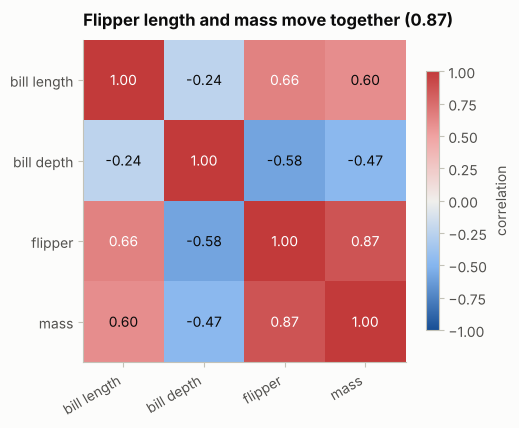

In [17]:
numeric = penguins[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]]
corr = numeric.corr()
labels = ["bill length", "bill depth", "flipper", "mass"]

fig, ax = plt.subplots(figsize=(5.2, 4.2))
im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(4), labels, rotation=30, ha="right")
ax.set_yticks(range(4), labels)
for i in range(4):
    for j in range(4):
        value = corr.values[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                color="white" if abs(value) > 0.6 else INK)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="correlation")
ax.set_title("Flipper length and mass move together (0.87)")
plt.show()

Correlations run from -1 to +1, with 0 meaning "no relationship", so this uses the **diverging** scale: blue for negative, red for positive, and neutral grey at zero. `vmin=-1, vmax=1` is essential. Without it, Matplotlib would stretch the colours to the smallest and largest values present, and a weak correlation could end up looking as strong as a perfect one.

The text colour switches to white on dark cells so the numbers stay readable. Writing the values in the cells is worthwhile here, since there are only 16 and readers will want the exact numbers.

One more lesson from section 6: this matrix pools all three species, so the bill length / depth correlation of -0.24 is the misleading pooled one. Correlation matrices hide Simpson's paradox too.

## 10. Seaborn

Seaborn is built on Matplotlib and works directly with pandas DataFrames: you name the columns, and it handles grouping, colours and legends. It's often the fastest way to explore data. To keep its colours consistent with ours, pass the palette and the order of the groups explicitly:

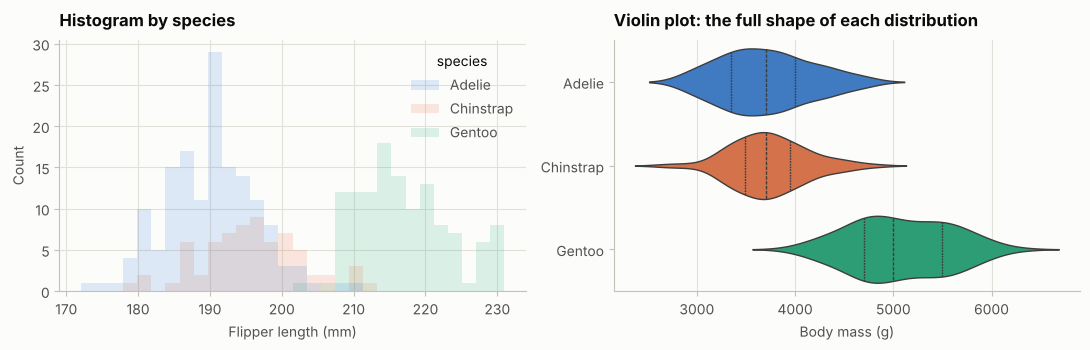

In [18]:
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(data=penguins, x="flipper_length_mm", hue="species", hue_order=SPECIES,
             palette=COLOURS, element="step", fill=True, alpha=0.15, bins=30, ax=axes[0])
axes[0].set_title("Histogram by species")
axes[0].set_xlabel("Flipper length (mm)")

sns.violinplot(data=penguins, x="body_mass_g", y="species", order=SPECIES, hue="species",
               hue_order=SPECIES, palette=COLOURS, inner="quartile", linewidth=1, ax=axes[1], legend=False)
axes[1].set_title("Violin plot: the full shape of each distribution")
axes[1].set_xlabel("Body mass (g)")
axes[1].set_ylabel("")
fig.tight_layout()
plt.show()

A violin plot is a box plot that also shows the shape: the width at each point shows how many values are near it. `inner="quartile"` draws the median and quartiles inside.

`hue_order` and `palette=COLOURS` (a dict from species to colour) guarantee that Adelie is blue here too. Without them, Seaborn would assign colours in whatever order the species first appear in the data, which can differ between datasets.

Seaborn labels axes with the raw column names, like `flipper_length_mm`. That's fine while exploring, but set readable labels before a chart goes anywhere else.

A **pair plot** draws a scatter plot for every pair of columns, with distributions on the diagonal. It's a quick first look at a new dataset:

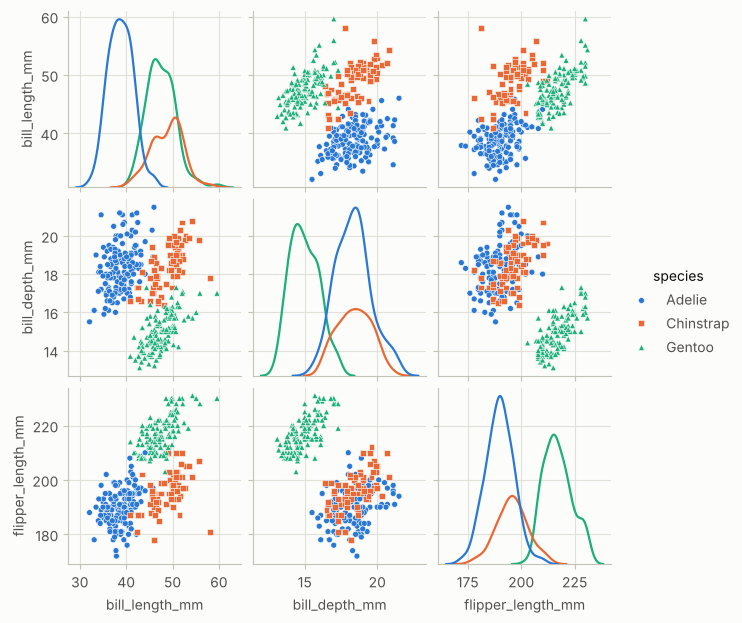

In [19]:
grid = sns.pairplot(penguins.sort_values("species"), vars=["bill_length_mm", "bill_depth_mm", "flipper_length_mm"],
                    hue="species", hue_order=SPECIES, palette=COLOURS,
                    markers=[MARKERS[s] for s in SPECIES], height=2.1,
                    plot_kws={"s": 18, "edgecolor": SURFACE, "linewidth": 0.4}, diag_kws={"fill": False})
plt.show()

The data is sorted by species first, which keeps Seaborn's marker shapes in the same order as the colours (it assigns markers in the order groups appear in the data). It's a good example of why it's worth checking a chart's legend against the marks rather than assuming they match.

Look at the bill length / bill depth panels: the species form three separate clusters, and the paradox from section 6 is visible right there. A pair plot is a quick way to find which pairs of features separate your classes, which is exactly the question before training a classifier.

## 11. Figures for reports

A chart in a notebook is for you. A chart in a report is for someone else, who wasn't there when you made it. A few things make the difference:

- **A title that states the finding.** "Gentoos weigh about 1.4 kg more" beats "Mean mass by species". The reader gets the point even if they look at nothing else.
- **Labelled axes with units.** "Body mass (g)", not `body_mass_g`.
- **A source note** saying where the data came from.
- **Accessible to everyone.** Not colour alone (use markers, labels, a legend), enough contrast, and a short text description ("alt text") wherever the image is used. For important numbers, a table alongside the chart is the most accessible version of all.

Saving is one call. PNG is right for most uses, and SVG keeps charts sharp at any size, which suits documents and web pages:

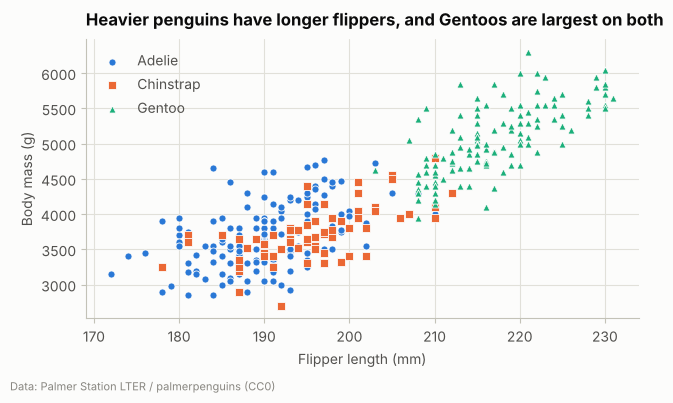

flipper_vs_mass.png 81,340 bytes
flipper_vs_mass.svg 95,311 bytes


In [20]:
out = Path("work") / "figures"
out.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(6.5, 4))
for sp in SPECIES:
    group = penguins[penguins["species"] == sp]
    ax.scatter(group["flipper_length_mm"], group["body_mass_g"], color=COLOURS[sp], marker=MARKERS[sp],
               s=26, edgecolors=SURFACE, linewidths=0.6, label=sp)
ax.set_xlabel("Flipper length (mm)")
ax.set_ylabel("Body mass (g)")
ax.set_title("Heavier penguins have longer flippers, and Gentoos are largest on both")
ax.legend(loc="upper left")
fig.text(0.01, 0.01, "Data: Palmer Station LTER / palmerpenguins (CC0)", color=MUTED, fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 1))

fig.savefig(out / "flipper_vs_mass.png", bbox_inches="tight")
fig.savefig(out / "flipper_vs_mass.svg", bbox_inches="tight")
plt.show()
plt.close(fig)

for p in sorted(out.iterdir()):
    print(p.name, f"{p.stat().st_size:,} bytes")

`bbox_inches="tight"` trims empty space around the figure, so labels near the edge aren't cut off. The PNG is saved at 150 dots per inch (set in the house style), sharper than the screen version.

`plt.close(fig)` frees the figure's memory. In a loop that makes hundreds of charts, say one per experiment, forgetting it slowly eats memory, and Matplotlib warns once more than 20 figures are open.

## Summary

- **Plot before you model.** Summary statistics can hide entirely different patterns (Anscombe's quartet).
- Use the object-oriented style: `fig, ax = plt.subplots()`, then `ax.plot`, `ax.set_title` and so on. Several panels are an array of axes.
- Set a house style once with `rcParams`: recessive grid and axes, thin marks, consistent colours.
- Colours have jobs: **categorical** for identity (fixed order, checked for colour blindness), **sequential** (one hue) for magnitude, **diverging** (two hues, grey midpoint) for values around zero. Never a rainbow.
- Colour follows the entity. Never rely on colour alone: add markers, labels or a legend.
- Choose the chart from the question. **One y-axis**. **Bars start at zero.**
- Histograms depend on the bin count. Use the same bins and shared axes for small multiples.
- Split by group before trusting a trend (Simpson's paradox).
- Fix overplotting with `alpha`, smaller markers or `hexbin`.
- Sort and label bar charts. Index series to a common base instead of using two axes.
- Heatmaps of correlations need `vmin=-1, vmax=1` and a diverging scale.
- Seaborn is quick for exploring; pass `hue_order` and `palette` to keep colours consistent.
- Titles state the finding. Save with `bbox_inches="tight"`, and `plt.close` figures in loops.

Next, open `02_exercises.ipynb`.